<a href="https://colab.research.google.com/github/omerbzk/pytorch-deep-learning-fundamentals/blob/master/01-ANN/ANN_Digit_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digit Classification using Artificial Neural Networks (ANN)

This notebook demonstrates how to build, train, and evaluate a simple Artificial Neural Network (ANN) using **PyTorch** to classify handwritten digits from the classic **MNIST dataset**.

## Project Workflow
1. **Environment & Libraries Setup**
2. **Data Preparation & Loading**
3. **Exploratory Data Visualization**
4. **Model Architecture Definition**
5. **Loss Function & Optimizer Setup**
6. **Model Training & Evaluation Pipeline**
7. **Execution & Results**

In [ ]:
### 1. Environment & Libraries Setup
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Configure device diagnostic
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [ ]:
### 2. Data Preparation & Loading
def get_data_loaders(batch_size=64):
    # Normalize images from [0, 255] to range [-1, 1]
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    # Download and load MNIST dataset
    train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size, shuffle=False)

    return train_loader, test_loader

In [ ]:
### 3. Exploratory Data Visualization

In [ ]:
def visualize_samples(loader, n=5):
    # Get a single batch of images and labels
    images, labels = next(iter(loader))
    fig, axes = plt.subplots(nrows=1, ncols=n, figsize=(12, 4))

    for i in range(n):
        axes[i].imshow(images[i].squeeze(), cmap='gray')
        axes[i].set_title(f"Label: {labels[i].item()}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

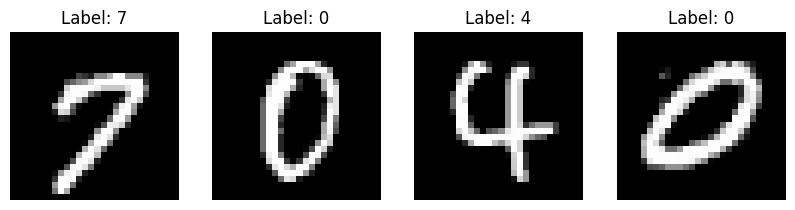

In [ ]:
### 4. Model Architecture Definition

In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        # Flatten 2D images (28x28) to 1D vectors (784)
        self.flatten = nn.Flatten()

        # Fully connected layers
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)  # 10 output classes (digits 0-9)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [ ]:
### 5. Loss Function & Optimizer Setup

In [ ]:
# Define standard loss function and Adam optimizer
def get_loss_and_optimizer(model, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    return criterion, optimizer

In [ ]:
### 6. Training Pipeline
def train_model(model, train_loader, criterion, optimizer, epochs=10):
    model.train()
    train_losses = []

    for epoch in range(epochs):
        total_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            optimizer.zero_grad()
            predictions = model(images)
            loss = criterion(predictions, labels)

            # Backward pass & optimization step
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        train_losses.append(avg_loss)
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {avg_loss:.4f}")

    # Plot training loss progression
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, epochs + 1), train_losses, marker='o', label='Train Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training Loss Progression')
    plt.legend()
    plt.grid(True)
    plt.show()

Epoch: 1/5, Loss: 0.3995
Epoch: 2/5, Loss: 0.1889
Epoch: 3/5, Loss: 0.1391
Epoch: 4/5, Loss: 0.1130
Epoch: 5/5, Loss: 0.0937


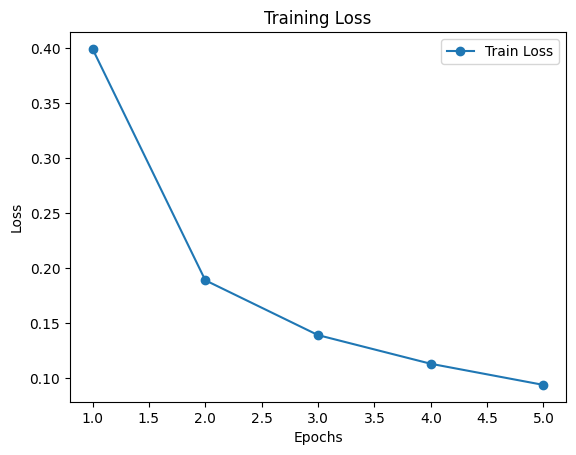

In [ ]:
# train_model(model, train_loader, criterion, optimizer, epochs=5)

In [ ]:
### 7. Evaluation Pipeline
def test_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images)
            _, predicted = torch.max(predictions, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Test Accuracy: {accuracy:.2f}%")

In [ ]:
### 8. Execution Pipeline

Test Accuracy: 96.97%


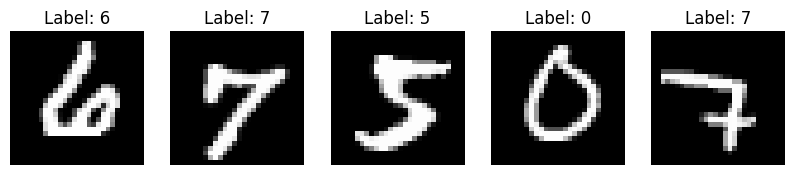

Epoch: 1/10, Loss: 0.3887
Epoch: 2/10, Loss: 0.1881
Epoch: 3/10, Loss: 0.1387
Epoch: 4/10, Loss: 0.1120
Epoch: 5/10, Loss: 0.0957
Epoch: 6/10, Loss: 0.0809
Epoch: 7/10, Loss: 0.0728
Epoch: 8/10, Loss: 0.0652
Epoch: 9/10, Loss: 0.0591
Epoch: 10/10, Loss: 0.0560


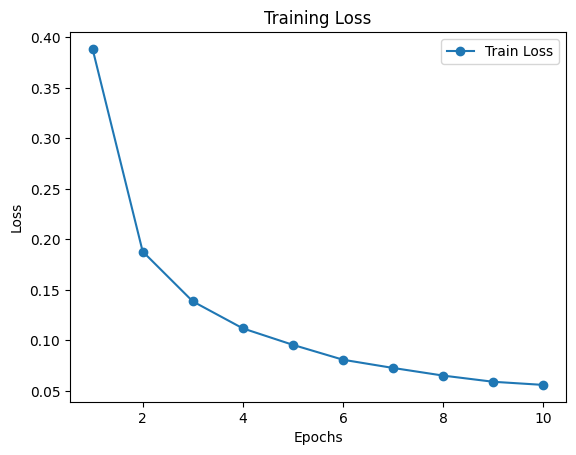

Test Accuracy: 97.37%


In [ ]:
if __name__ == "__main__":
    # 1. Load data
    train_loader, test_loader = get_data_loaders(batch_size=64)

    # 2. Visualize samples
    visualize_samples(train_loader, n=5)

    # 3. Initialize Model, Loss and Optimizer
    model = NeuralNetwork().to(device)
    criterion, optimizer = get_loss_and_optimizer(model, lr=0.001)

    # 4. Train model
    train_model(model, train_loader, criterion, optimizer, epochs=5)

    # 5. Evaluate model
    test_model(model, test_loader)